# PRISM-BioReason Model Architecture

![PRISM-BioReason model architecture](flow-diag.png)

# BioReason on Aurora: training a DNA + language model with PRISM

This notebook trains **BioReason-style DNA reasoning** with PRISM: an LLM reads a reference and a variant DNA sequence, then answers *"which disease does this variant contribute to?"*. It runs on **one Aurora interactive node** (12 PVC tiles).

Key stages of training and respective files:
| Stage | Config (`src/conf/training/`) | Trains | Frozen | Script |
|---|---|---|---|---|
| 1. Projector alignment | `bioreason_projector.yaml` | DNA projector | NT encoder, OLMo | `scripts/training/submit_bioreason_projector.sh` |
| 2. SFT | `bioreason_sft.yaml` | projector + LoRA (r=32) | NT encoder, OLMo base | `scripts/training/submit_bioreason_sft.sh` |
| 3. GRPO | `bioreason_grpo.yaml` | LoRA (r=16, on top of merged SFT LoRA) | everything else | `scripts/training/submit_bioreason_grpo_aurora.sh` |
| 4. Eval | — | — | — | `scripts/eval/submit_eval_kegg_aurora.sh` |

**Sections**
0. Environment installation (terminal, once)
1. Settings and environment variables (HF cache)
2. Prerequisites
3. Download models and data from Hugging Face
4. Visualize the data
5. `datasets_config.json`: where datasets are registered
6. How the DNA modality is registered
7. Pointing at the DNA encoder
8. Special tokens
9. Model build: inspect, then modify the projector and LoRA
10. One batch end to end (tokenization view and forward pass)
11. Local smoke run on this node
12. Submitting all four stages with `qsub`
13. Monitoring and results
14. Troubleshooting

> **Before you start:** follow section 0 to build the environment and connect this notebook to the **PRISM BioReason (Aurora)** kernel.

## Environment installation (once, in a terminal, before opening this notebook)

The notebook's kernel *is* this environment, so build it from a shell first. It follows the README's Aurora rules (`uv`-managed venv on `/flare`, PRISM installed with `--no-deps` so pip never replaces the module's XPU PyTorch, frameworks module loaded **before** the venv), with one difference noted at the end.

**① On a login node** (it has direct internet access):
```bash
# uv (README: required by the Aurora env builders)
curl -LsSf https://astral.sh/uv/install.sh | sh

# code
git clone https://github.com/AI-ModCon/BaseMM_PRISM.git
cd BaseMM_PRISM && git checkout bioreason_tutorial

# venv + Jupyter kernel: loads frameworks/2026.1.0, creates a --system-site-packages
# venv at /flare/ModCon/$USER/prism-envs/bioreason-fw2026.1, installs the extras the module
# lacks (torchtune, webdataset, wandb, ipykernel, ipywidgets, jupyter_server) with --no-deps,
# installs PRISM itself with --no-deps, and registers the "PRISM BioReason (Aurora)" kernel.
bash applications/bioreason/helpers/setup_jupyter_kernel.sh

# on the compute node
module use /soft/modulefiles && module load frameworks/2026.1.0      # module first ...

python -m venv .venv && source .venv/bin/activate
pip install -r requirements/base.txt
pip install -e . --no-deps

source /flare/ModCon/$USER/$PROJECT/BaseMM_PRISM/.venv/bin/activate  # ... then the venv
cd /flare/ModCon/$USER/$PROJECT/BaseMM_PRISM            # wherever you cloned it

# Connect Jupyter notebook to interactive compute node. 

** Get a compute node and start a Jupyter server on it:**
```

```bash

qsub -I -l select=1 -l walltime=1:00:00 -q debug -A ModCon -l filesystems=home:flare

source /flare/ModCon/$USER/$PROJECT/BaseMM_PRISM/.venv/bin/activate  # ... then the venv

jupyter server --no-browser --ip=$(hostname -f) --port 8888     # prints the URL + a new random token

```

Lost the Jupyter URL? 
Run `jupyter server list` on the node. 

To reuse **one fixed token** across nodes, create it once with 
`python3 -c "import secrets; print(secrets.token_hex(24))" > ~/.jupyter_token && chmod 600 ~/.jupyter_token`, then start the server with:

```bash
test -s ~/.jupyter_token && jupyter server --no-browser --ip=$(hostname -f) --port 8888 \
    --IdentityProvider.token="$(cat ~/.jupyter_token)"
```

**③ Connect VS Code** (Remote-SSH to the login node):

1. **Select Kernel → Select Another Kernel… → Existing Jupyter Server**, paste `http://<node>.hostmgmt.cm.aurora.alcf.anl.gov:8888/?token=<token>`. Use the **full** hostname: it matches `no_proxy=*.alcf.anl.gov`, so the request isn't routed through the ALCF proxy (`502 Bad Gateway`).
2. Pick **PRISM BioReason (Aurora)**, not "Python 3".
3. If it hangs on "Connecting to kernel", set `"http.proxySupport": "off"` in **Remote Settings** and run **Developer: Reload Window**. `403 Forbidden` means a stale token: each server start makes a new one unless you use a fixed token.

**④ Optional site paths.** The README's `PRISM_*` variables (`cp .env.template .env`, Aurora values in `.env.aurora.example`) are **not** needed here: section 1 sets everything this notebook and its jobs use.

> **Why not `tools/build_aurora_env.sh`?** The README's canonical Aurora build pins `frameworks/2025.3.1` and its lockfile. The BioReason submit scripts and this tutorial run on **`frameworks/2026.1.0`**, the stack everything here was tested on, which is why they use their own venv. Don't mix the two: a venv built against one frameworks module and loaded under the other fails with import or ABI errors. Note that 2026.1.0 ships transformers 5.x, so only Nucleotide Transformer **v1** checkpoints (e.g. the 2.5B multi-species one used here) load. NT-v2's remote code doesn't.

Section 2 below verifies the result (12 XPU tiles, venv active, no missing packages).

## 1. Settings and environment variables

Everything site-specific is set here and nowhere else. Later sections pass the same values to batch jobs through `qsub -v`.

| Variable | Why |
|---|---|
| `HF_HOME` | Hugging Face cache for **models and datasets**. It must be on `/flare`: home has a small quota, and an earlier projector job died with `Disk quota exceeded` at its first checkpoint. The submit scripts look for `$HF_HOME/hub/models--…`. |
| `PRISM_DATA_ROOT` | `datasets_config.json` resolves `${PRISM_DATA_ROOT}/dna_local_shards/kegg` from it. |
| `PRISM_CKPT_ROOT` | Checkpoints (~13 GB each): every run writes to `$PRISM_CKPT_ROOT/<RUN_ID>/<RUN_TAG>` (`hydra.run.dir`). |
| `PRISM_OUTPUT_ROOT` | Logs, eval results, and generated scripts. |
| `HTTP(S)_PROXY` | Aurora compute nodes reach the internet only through the ALCF proxy. |
| `HF_HUB_OFFLINE` | Off while downloading (section 3), on for training, which is what the batch jobs do. |
| `MAX_SEQ_LENGTH` | Cap on the **merged** sequence (text + 2 × 1024 DNA slots ≈ 2.8–3.6k tokens for KEGG). The 2048 default makes the merged-length guard reject every DNA example (section 10). |

In [1]:
import os, sys, getpass, datetime
from pathlib import Path

USER    = getpass.getuser()
PROJECT = "ModCon"                       # PBS allocation (-A)

REPO              = Path.cwd().resolve().parents[1] if Path.cwd().name == "bioreason" else Path.cwd().resolve()
PRISM_DATA_ROOT   = f"/lus/flare/projects/{PROJECT}/{USER}/cache"
PRISM_OUTPUT_ROOT = f"/lus/flare/projects/{PROJECT}/{USER}/output"
PRISM_CKPT_ROOT   = f"/lus/flare/projects/{PROJECT}/{USER}/modcon/checkpoints"   # = the submit scripts' default
HF_HOME           = f"/flare/{PROJECT}/{USER}/cache/model_weights"   # = the submit scripts' HF_HOME
PRISM_VENV        = os.environ.get("PRISM_VENV", f"/flare/{PROJECT}/{USER}/prism-envs/bioreason-fw2026.1")
PROXY             = "http://proxy.alcf.anl.gov:3128"

RUN_TAG = datetime.datetime.now().strftime("demo-%Y%m%d-%H%M")   # one tag for all runs from this session
SUBMIT  = False      # flip to True in section 12 to actually qsub

ENV = {
    "PRISM_DATA_ROOT": PRISM_DATA_ROOT,
    "PRISM_OUTPUT_ROOT": PRISM_OUTPUT_ROOT,
    "PRISM_CKPT_ROOT": PRISM_CKPT_ROOT,
    "PRISM_VENV": PRISM_VENV,
    "HF_HOME": HF_HOME,
    "HF_HUB_CACHE": f"{HF_HOME}/hub",
    "HTTP_PROXY": PROXY, "HTTPS_PROXY": PROXY, "http_proxy": PROXY, "https_proxy": PROXY,
    "no_proxy": "localhost,127.0.0.1,.alcf.anl.gov",
    "WANDB_MODE": "offline",
    "MAX_SEQ_LENGTH": "4096",
    "TOKENIZERS_PARALLELISM": "false",
}
os.environ.update(ENV)
for d in (PRISM_DATA_ROOT, PRISM_OUTPUT_ROOT, PRISM_CKPT_ROOT, HF_HOME):
    Path(d).mkdir(parents=True, exist_ok=True)

os.chdir(REPO)                      # model YAMLs use repo-relative tokenizer paths
sys.path.insert(0, str(REPO))
sys.path.insert(0, str(REPO / "applications" / "bioreason"))
sys.path.insert(0, str(REPO / "applications" / "bioreason" / "helpers"))
import demo_helpers as H   # applications/bioreason/helpers/demo_helpers.py

print("repo   ", REPO)
print("run tag", RUN_TAG)
for k in ("HF_HOME", "PRISM_DATA_ROOT", "PRISM_CKPT_ROOT", "PRISM_OUTPUT_ROOT"):
    print(f"{k:18s}", ENV[k])

repo    /home/abalaji/projects/modcon/release/BaseMM_PRISM
run tag demo-20261011-2324
HF_HOME            /flare/ModCon/abalaji/cache/model_weights
PRISM_DATA_ROOT    /lus/flare/projects/ModCon/abalaji/cache
PRISM_CKPT_ROOT    /lus/flare/projects/ModCon/abalaji/modcon/checkpoints
PRISM_OUTPUT_ROOT  /lus/flare/projects/ModCon/abalaji/output


## 2. Prerequisites

PRISM on Aurora uses the **`frameworks/2026.1.0`** module (XPU PyTorch, oneCCL) plus a thin `--system-site-packages` venv holding only what the module lacks: `torchtune` for LoRA, `webdataset`, `wandb`, and `ipywidgets` for this notebook. Extras are installed with `--no-deps` so pip never swaps the module's XPU torch for a CUDA wheel.

> Do **not** activate the repo's `.venv`. It carries a CUDA torch build, and its transformers 5.x can't run the Nucleotide Transformer **v2** remote code (see section 7).

In [2]:
import importlib, torch, transformers

print("python      ", sys.executable)
print("in venv     ", Path(sys.prefix).resolve() == Path(PRISM_VENV).resolve(), f"(sys.prefix={sys.prefix})")
print("torch       ", torch.__version__, "| transformers", transformers.__version__)
print("XPU tiles   ", torch.xpu.device_count() if hasattr(torch, "xpu") else 0, "(expect 12 on an Aurora node)")
missing = [m for m in ("torchtune", "webdataset", "ipywidgets", "hydra", "datasets", "wandb")
           if importlib.util.find_spec(m) is None]
print("missing     ", missing or "none")

python       /flare/ModCon/abalaji/prism-envs/bioreason-fw2026.1/bin/python
in venv      True (sys.prefix=/flare/ModCon/abalaji/prism-envs/bioreason-fw2026.1)
torch        2.13.0a0+gitcf30153 | transformers 5.14.1
XPU tiles    12 (expect 12 on an Aurora node)
missing      none


In [3]:
# Only needed if something is listed as missing above (same recipe as the submit scripts' header).
if missing:
    !uv pip install wandb braceexpand==0.1.7 ipywidgets
    !uv pip install --no-deps webdataset==1.0.2 torchtune==0.6.1
    !uv pip install --no-deps -e {REPO}
    print("Installed - restart the kernel and re-run section 1.")

## 3. Download models and data from Hugging Face

**Models.** `snapshot_download` is called *without* `cache_dir`, so files land under `$HF_HOME/hub/models--<org>--<name>`. That's the layout `transformers` resolves offline, and the layout the submit scripts' pre-flight checks look for.

| Model | Role | Size |
|---|---|---|
| `allenai/OLMo-1B-0724-hf` | LLM backbone (d_model 2048) | ~4.7 GB |
| `InstaDeepAI/nucleotide-transformer-2.5b-multi-species` | DNA encoder **and** DNA tokenizer (6-mers) | ~10 GB |

In [4]:
os.environ["HF_HUB_OFFLINE"] = "0"
from huggingface_hub import snapshot_download

MODELS = {
    "llm": "allenai/OLMo-1B-0724-hf",
    "dna": "InstaDeepAI/nucleotide-transformer-2.5b-multi-species",
}
SNAPSHOTS = {}
for role, repo_id in MODELS.items():
    local = Path(HF_HOME, "hub", "models--" + repo_id.replace("/", "--"))
    SNAPSHOTS[role] = snapshot_download(repo_id, local_files_only=local.exists())
    print(f"{role}: {repo_id}\n     -> {SNAPSHOTS[role]}")

llm: allenai/OLMo-1B-0724-hf
     -> /flare/ModCon/abalaji/cache/model_weights/hub/models--allenai--OLMo-1B-0724-hf/snapshots/d7cbab742d80589e714b1a2d7f838dcd21cbe143
dna: InstaDeepAI/nucleotide-transformer-2.5b-multi-species
     -> /flare/ModCon/abalaji/cache/model_weights/hub/models--InstaDeepAI--nucleotide-transformer-2.5b-multi-species/snapshots/b746b125aacd1b0970c05a32fd71ba726754542e


**Data.** 

`helpers/download_bioreason_dna_datasets.py` saves each Hugging Face dataset with `save_to_disk` (Arrow) under `<output-dir>/<key>/`. 

PRISM's streaming loader globs `*.arrow` from the `local_path` given in `datasets_config.json`, so training never touches the Hub.

| Dataset | Rows (train) | Fields |
|---|---|---|
| `wanglab/kegg` | 1,159 | `question, answer, reasoning, reference_sequence, variant_sequence` |
| `wanglab/variant_effect_coding` | 48,850 | `question, answer, reference_sequence, variant_sequence` |
| `wanglab/variant_effect_non_snv` | 35,215 | `question, answer, reference_sequence, mutated_sequence` |

KEGG's `val` and `test` splits go to separate roots, because the script names the output folder after the dataset, not the split.

In [5]:
DL = REPO / "applications/bioreason/helpers/download_bioreason_dna_datasets.py"
SHARDS = Path(PRISM_DATA_ROOT, "dna_local_shards")

for key in ("kegg", "variant_effect_coding", "variant_effect_non_snv"):
    if not (SHARDS / key / "dataset_info.json").exists():
        !python {DL} --dataset {key} --output-dir {SHARDS}
for split in ("val", "test"):
    if not Path(PRISM_DATA_ROOT, f"dna_local_shards_{split}", "kegg", "dataset_info.json").exists():
        !python {DL} --dataset kegg --split {split} --output-dir {PRISM_DATA_ROOT}/dna_local_shards_{split}

os.environ["HF_HUB_OFFLINE"] = "1"      # from here on, run like the batch jobs: fully offline
os.environ["HF_DATASETS_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"
!find {SHARDS} {PRISM_DATA_ROOT}/dna_local_shards_val {PRISM_DATA_ROOT}/dna_local_shards_test -maxdepth 2 -name "*.arrow" -o -maxdepth 2 -name dataset_info.json | sort

find: warning: you have specified the global option -maxdepth after the argument -name, but global options are not positional, i.e., -maxdepth affects tests specified before it as well as those specified after it.  Please specify global options before other arguments.
/lus/flare/projects/ModCon/abalaji/cache/dna_local_shards/kegg/data-00000-of-00001.arrow
/lus/flare/projects/ModCon/abalaji/cache/dna_local_shards/kegg/dataset_info.json
/lus/flare/projects/ModCon/abalaji/cache/dna_local_shards_test/kegg/data-00000-of-00001.arrow
/lus/flare/projects/ModCon/abalaji/cache/dna_local_shards_test/kegg/dataset_info.json
/lus/flare/projects/ModCon/abalaji/cache/dna_local_shards_val/kegg/data-00000-of-00001.arrow
/lus/flare/projects/ModCon/abalaji/cache/dna_local_shards_val/kegg/dataset_info.json
/lus/flare/projects/ModCon/abalaji/cache/dna_local_shards/variant_effect_coding/data-00000-of-00001.arrow
/lus/flare/projects/ModCon/abalaji/cache/dna_local_shards/variant_effect_coding/dataset_info.json

## 4. Multimodal task the model is being trained for and the respective datasets

kegg                       1,159 rows  columns=['question', 'answer', 'reasoning', 'reference_sequence', 'variant_sequence']
variant_effect_coding     48,850 rows  columns=['ID', 'question', 'answer', 'reference_sequence', 'variant_sequence']
variant_effect_non_snv    35,215 rows  columns=['question', 'answer', 'reference_sequence', 'mutated_sequence', 'cleaned_pathogenicity', '__index_level_0__']
kegg (test)                  146 rows  columns=['question', 'answer', 'reasoning', 'reference_sequence', 'variant_sequence']


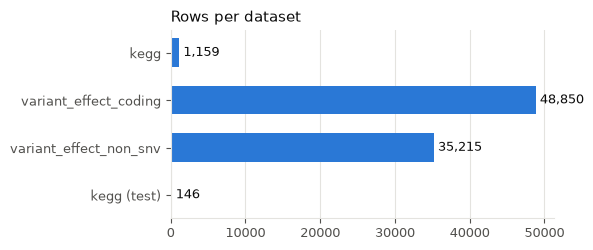

In [37]:
from datasets import load_from_disk
import matplotlib.pyplot as plt
from IPython.display import HTML, display

DS = {k: load_from_disk(str(SHARDS / k)) for k in ("kegg", "variant_effect_coding", "variant_effect_non_snv")}
DS["kegg (test)"] = load_from_disk(f"{PRISM_DATA_ROOT}/dna_local_shards_test/kegg")
for k, d in DS.items():
    print(f"{k:24s} {len(d):>7,} rows  columns={d.column_names}")
H.plot_counts({k: len(d) for k, d in DS.items()}, "Rows per dataset");

### Sample browser

Pick a dataset and a row. Bases are colored by letter, and the positions where the variant differs from the reference are highlighted: single-base substitutions in `variant_effect_coding`, insertions and deletions in `variant_effect_non_snv`. Only a window around the first difference is shown.

In [38]:
H.sample_browser(DS)

### How long are the sequences, in tokens?

The model doesn't see base pairs. The NT tokenizer turns DNA into **6-mers** (≈ bp / 6), and every DNA span is padded or truncated to exactly `max_dna_length = 1024` tokens. That fixed length is what makes the splice in section 10 work. Text goes through the OLMo tokenizer.

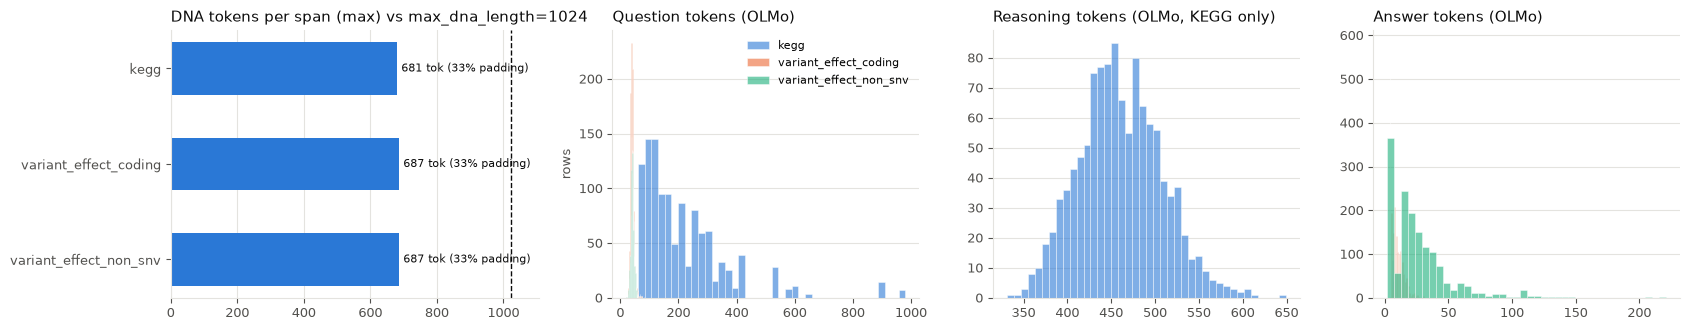

dataset                  kegg  variant_effect_coding  variant_effect_non_snv
ref_bp           mean  4006.0                 4096.0                  4096.0
                 50%   4001.0                 4096.0                  4096.0
                 max   4070.0                 4096.0                  4096.0
var_bp           mean  4008.0                 4096.0                  4096.0
                 50%   4001.0                 4096.0                  4096.0
                 max   4260.0                 4096.0                  4096.0
ref_dna_tokens   mean   672.0                  687.0                   687.0
                 50%    672.0                  687.0                   687.0
                 max    681.0                  687.0                   687.0
question_tokens  mean   216.0                   40.0                    42.0
                 50%    165.0                   39.0                    42.0
                 max    980.0                   82.0                    59.0
answer_tokens    mean     5.0                   11.0                    26.0
                 50%      4.0                   10.0                    20.0
                 max     10.0                   32.0                   221.0
reasoning_tokens mean   460.0                    0.0                     0.0
                 50%    458.0                    0.0                     0.0
                 max    649.0                    0.0                     0.0

share of reference spans truncated at 1024 tokens: {'kegg': 0.0, 'variant_effect_coding': 0.0, 'variant_effect_non_snv': 0.0}


In [39]:
from transformers import AutoTokenizer
llm_tok = AutoTokenizer.from_pretrained("tokenizers/prism-olmo-1b-interleaved")
dna_tok = AutoTokenizer.from_pretrained(SNAPSHOTS["dna"], trust_remote_code=True)

LEN = H.length_frame({k: DS[k] for k in ("kegg", "variant_effect_coding", "variant_effect_non_snv")},
                     llm_tok, dna_tok, max_rows=1500)
H.plot_lengths(LEN, max_dna_length=1024); plt.show()
display(LEN.groupby("dataset").describe().T.loc[(slice(None), ["mean", "50%", "max"]), :].round(0))
print("share of reference spans truncated at 1024 tokens:",
      LEN.assign(t=LEN.ref_dna_tokens > 1024).groupby("dataset").t.mean().round(3).to_dict())

37 distinct KEGG answers; top 15 cover 85%


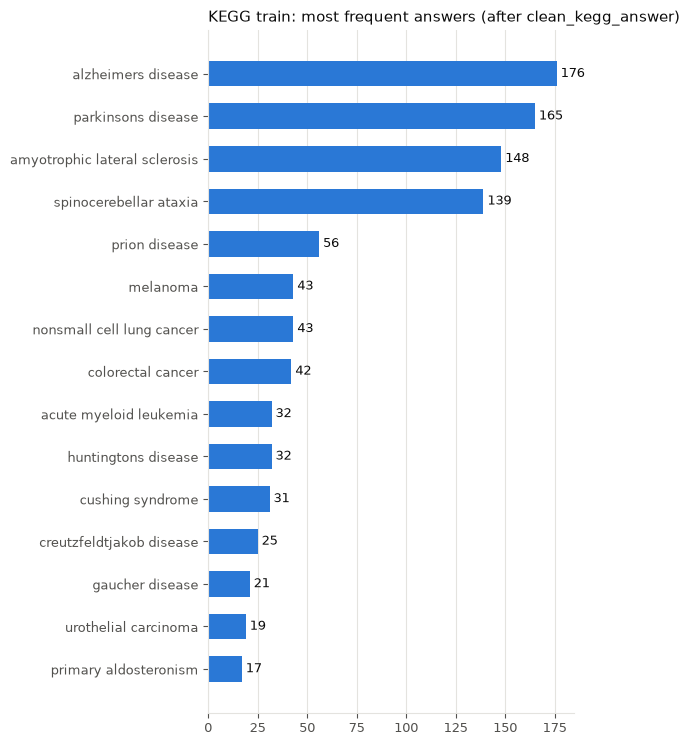

In [40]:
from collections import Counter
from src.data.multimodal import clean_kegg_answer
answers = Counter(clean_kegg_answer(a) for a in DS["kegg"]["answer"])
print(f"{len(answers)} distinct KEGG answers; top 15 cover {sum(c for _, c in answers.most_common(15)) / len(DS['kegg']):.0%}")
H.plot_counts(dict(answers.most_common(15)), "KEGG train: most frequent answers (after clean_kegg_answer)");

## 5. `datasets_config.json`: where datasets are registered

Every dataset PRISM can stream is an entry in `src/data/datasets_config.json`. Here is the KEGG entry:

In [10]:
H.show_source("src/data/datasets_config.json", pattern=r'"dna_bioreason": \{', context=22)

`src/data/datasets_config.json:394-415`
```json
  394              "dna_bioreason": {
  395                  "name": "DNA sequences",
  396                  "hf_id": "wanglab/kegg",
  397                  "split": "train",
  398                  "weight": 0.50,
  399                  "handler": "dna_bioreason",
  400                  "modality": "dna",
  401                  "local_path": "${PRISM_DATA_ROOT}/dna_local_shards/kegg",
  402                  "preferred_source": "local",
  403                  "required_keys": [
  404                      "question",
  405                      "answer",
  406                      "reasoning",
  407                      "reference_sequence",
  408                      "variant_sequence"
  409                  ],
  410                  "fallback_dummy": false,
  411                  "skip": false,
  412                  "size_formatted": "1,159 samples (train split)"
  413              },
  414              "dna_bioreason_variant_effect_coding": {
  415                  "name": "Variant Effect (Coding)",
```

| Field | Meaning |
|---|---|
| `handler` | Picks the `_process_<handler>` method in `src/data/multimodal.py` that turns a raw row into a chat prompt + DNA (section 6). |
| `modality` | The modality group it is sampled under (`dna`). Sampling first picks a modality, then a dataset within it by `weight`. |
| `local_path` / `preferred_source` | `local` loads the Arrow files from section 3. `${PRISM_DATA_ROOT}` is expanded from the environment. |
| `hf_id` | Hub fallback, and the id that `training.bioreason_dataset` refers to. |
| `required_keys` | Columns that must exist. A dataset missing one fails loudly at load time. |
| `skip` | `true` excludes the dataset. Training presets flip this per run instead of editing the JSON. |

**Per-run overrides.** Each BioReason training preset composes `src/conf/data/bioreason_kegg_only.yaml`, which patches entries without touching the JSON:

In [11]:
H.show_source("src/conf/data/bioreason_kegg_only.yaml")

`src/conf/data/bioreason_kegg_only.yaml:1-16`
```yaml
    1  # BioReason KEGG-only data mix (wanglab/kegg via the dna_bioreason handler).
    2  # Pins every zone_a dataset that is default-on in datasets_config.json off, so
    3  # the SFT run cannot silently mix in another stream (ts_qa is skip=false there).
    4  #
    5  # Composed automatically by training=bioreason_{projector,sft,grpo} via their
    6  # defaults list (/data@_global_.data) -- do not also pass +data=bioreason_kegg_only.
    7  dataset_overrides:
    8    dna_bioreason:
    9      skip: false
   10      preferred_source: local
   11    dna_bioreason_variant_effect_coding:
   12      skip: true
   13    dna_bioreason_variant_effect_non_snv:
   14      skip: true
   15    ts_qa:
   16      skip: true
```

### Adding data: a KEGG + variant-effect mix

The original BioReason recipe mixes KEGG with the variant-effect sets (weights 0.5 / 0.25 / 0.25). The variant-effect entries already exist in the JSON, so a **new data YAML** that turns them on and points them at our downloads is all it takes. Passing `data=bioreason_demo_mix` on the command line swaps it in for `bioreason_kegg_only`.

Because it *replaces* `bioreason_kegg_only`, it has to pin every default-on stream itself (`ts_qa`). `${oc.env:PRISM_DATA_ROOT}` is resolved when the job starts.

In [12]:
MIX_YAML = REPO / "src/conf/data/bioreason_demo_mix.yaml"
MIX_YAML.write_text('''\
# Written by applications/bioreason/bioreason_demo.ipynb (section 5).
# KEGG + variant-effect mix (BioReason weights). Use with: data=bioreason_demo_mix
dataset_overrides:
  dna_bioreason:
    skip: false
    preferred_source: local
    weight: 0.5
  dna_bioreason_variant_effect_coding:
    skip: false
    preferred_source: local
    weight: 0.25
    local_path: ${oc.env:PRISM_DATA_ROOT}/dna_local_shards/variant_effect_coding
  dna_bioreason_variant_effect_non_snv:
    skip: false
    preferred_source: local
    weight: 0.25
    local_path: ${oc.env:PRISM_DATA_ROOT}/dna_local_shards/variant_effect_non_snv
  ts_qa:
    skip: true
''')
print(MIX_YAML.read_text())

# Written by applications/bioreason/bioreason_demo.ipynb (section 5).
# KEGG + variant-effect mix (BioReason weights). Use with: data=bioreason_demo_mix
dataset_overrides:
  dna_bioreason:
    skip: false
    preferred_source: local
    weight: 0.5
  dna_bioreason_variant_effect_coding:
    skip: false
    preferred_source: local
    weight: 0.25
    local_path: ${oc.env:PRISM_DATA_ROOT}/dna_local_shards/variant_effect_coding
  dna_bioreason_variant_effect_non_snv:
    skip: false
    preferred_source: local
    weight: 0.25
    local_path: ${oc.env:PRISM_DATA_ROOT}/dna_local_shards/variant_effect_non_snv
  ts_qa:
    skip: true



Validate the new mix the way the loader will: resolve the overrides, check each `local_path` exists, and check its Arrow columns against `required_keys`.

In [13]:
import glob
from hydra import initialize_config_dir, compose
from hydra.core.global_hydra import GlobalHydra
import pandas as pd
import src.train as T
from src.data.dataset_manager import DatasetManager

def compose_cfg(*overrides):
    # Same composition as `python src/train.py <overrides>`.
    GlobalHydra.instance().clear()
    with initialize_config_dir(config_dir=str(REPO / "src/conf"), version_base=None):
        return compose(config_name="config", overrides=list(overrides))

cfg_mix = compose_cfg("model=prism_olmo_1b", "training=bioreason_sft",
                      "training.resume_weights_only=null", "data=bioreason_demo_mix")
overrides = T._resolve_dataset_overrides(cfg_mix)
entries = DatasetManager().get_zone_config("zone_a")["datasets"]

rows = []
for name, ov in overrides.items():
    e = {**entries[name], **ov}
    if e.get("skip"):
        continue
    path = os.path.expandvars(e["local_path"])
    cols = set(load_from_disk(path).column_names) if glob.glob(f"{path}/*.arrow") else set()
    rows.append({"dataset": name, "weight": e["weight"], "local_path": path,
                 "arrow found": bool(cols), "missing required_keys": sorted(set(e["required_keys"]) - cols)})
display(pd.DataFrame(rows).set_index("dataset"))

W1011 23:25:11.983000 1232379 site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1011 23:25:12.007000 1232379 site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


,weight,local_path,arrow found,missing required_keys
dataset,,,,
dna_bioreason,0.50,/lus/flare/projects/ModCon/abalaji/cache/dna_l...,True,[]
dna_bioreason_variant_effect_coding,0.25,/lus/flare/projects/ModCon/abalaji/cache/dna_l...,True,[]
dna_bioreason_variant_effect_non_snv,0.25,/lus/flare/projects/ModCon/abalaji/cache/dna_l...,True,[]


<details><summary>Registering a <b>new</b> dataset, rather than enabling an existing one</summary>

Add an entry under `zone_a.datasets` in `src/data/datasets_config.json` with the fields above. Reuse an existing `handler` if the row schema matches (e.g. `dna_bioreason_variant_effect_coding` for `question/answer/reference_sequence/variant_sequence`). Otherwise, add a `_process_<handler>` method plus a branch in the handler dispatch (section 6). Then run `pytest tests/data/test_dna_bioreason_datasets_config.py`, which pins the DNA entries' schema.
</details>

## 6. How the DNA modality is registered

PRISM has no plugin registry. A modality is wired in through a handful of explicit touch points, and following DNA through them is the best map for adding your own.

**① The enum.** Every modality is a member of `Modality`. `ModelConfig.modalities` (`[text, dna]` in `prism_olmo_1b.yaml`) selects which ones a model builds.

In [ ]:
H.show_source("src/modalities.py", pattern=r"^class Modality", context=30)

`src/modalities.py:23-36`
```python
   23  class Modality(str, Enum):
   24      """The modality identifiers PRISM recognizes.
   25  
   26      Members are the canonical lowercase strings used as keys throughout the
   27      framework: ``config.modalities``, the ``encoders``/``projectors``
   28      ModuleDicts on ``UnifiedTransformer``, batch example dicts, and the
   29      ``modality`` field in ``datasets_config.json``.
   30  
   31      Because the enum subclasses ``str``, a member compares equal to and
   32      hashes like its value, so ``Modality.IMAGE == "image"`` is True and
   33      ``d[Modality.IMAGE]`` and ``d["image"]`` reach the same entry. The
   34      explicit ``__str__`` below -- not the ``str`` base -- is what makes
   35      ``str(Modality.IMAGE)`` render as ``"image"`` instead of
   36      ``"Modality.IMAGE"``; removing it would change f-string and log output.
```

**② The encoder** subclasses `ModalityEncoder`. `DNAEncoder` loads any HF masked-LM checkpoint, probes its hidden size, and adds a `Linear` when that differs from `d_dna`. `tokens_per_instance()` is the fixed number of embeddings one DNA span becomes.

In [15]:
H.show_source("src/encoders/dna.py", pattern=r"class DNAEncoder", context=45)

`src/encoders/dna.py:14-58`
```python
   14  class DNAEncoder(ModalityEncoder):
   15      """
   16      DNA sequence encoder using Nucleotide Transformer (NT) or Evo2.
   17  
   18      Supports:
   19        - InstaDeepAI/nucleotide-transformer-v2-500m-multi-species (default)
   20        - togethercomputer/evo2_1b_base (set dna_is_evo2=True)
   21  
   22      Input: Tokenized DNA sequences (B, T) as input_ids
   23      Output: Sequence features (B, T, d_dna)
   24      """
   25  
   26      def __init__(
   27          self,
   28          d_dna: int = 1024,
   29          model_name: str = "InstaDeepAI/nucleotide-transformer-v2-500m-multi-species",
   30          dna_is_evo2: bool = False,
   31          max_dna_length: int | None = None,
   32      ):
   33          super().__init__(d_dna)
   34          self.model_name = model_name
   35          self._max_dna_length_override = max_dna_length
   36  
   37          logger.info(f"Loading DNA Encoder: {model_name}...")
   38          self.model = AutoModelForMaskedLM.from_pretrained(model_name, trust_remote_code=True)
   39  
   40          # Probe the actual hidden state dimension by requesting output_hidden_states.
   41          # AutoModelForMaskedLM.outputs[0] = LM-head logits (vocab_size ~4096), NOT hidden
   42          # states. Using hidden_states[-1] gives the last encoder layer's representation,
   43          # which is what downstream tasks want.
   44          with torch.no_grad():
   45              dummy_ids = torch.zeros(1, 6, dtype=torch.long)
   46              try:
   47                  dummy_out = self.model(dummy_ids, output_hidden_states=True)
   48                  if (
   49                      hasattr(dummy_out, "hidden_states")
   50                      and dummy_out.hidden_states is not None
   51                      and len(dummy_out.hidden_states) > 0
   52                  ):
   53                      model_hidden_size = dummy_out.hidden_states[-1].shape[-1]
   54                      logger.info(f"DNA model hidden_states[-1] dim (probed): {model_hidden_size}")
   55                  elif hasattr(dummy_out, "last_hidden_state") and dummy_out.last_hidden_state is not None:
   56                      model_hidden_size = dummy_out.last_hidden_state.shape[-1]
   57                      logger.info(f"DNA model last_hidden_state dim (probed): {model_hidden_size}")
   58                  else:
```

**③ Model wiring.** `UnifiedTransformer.__init__` builds the encoder and its projector when the modality is enabled:

In [16]:
H.show_source("src/model.py", pattern=r"if Modality.DNA in config.modalities", context=34)

`src/model.py:590-623`
```python
  590          if Modality.DNA in config.modalities:
  591              dna_model_name = getattr(
  592                  config,
  593                  "dna_model_name",
  594                  "InstaDeepAI/nucleotide-transformer-2.5b-multi-species",
  595              )
  596              dna_is_evo2 = getattr(config, "dna_is_evo2", False)
  597  
  598              self.encoders["dna"] = DNAEncoder(
  599                  d_dna=config.d_dna,
  600                  model_name=dna_model_name,
  601                  dna_is_evo2=dna_is_evo2,
  602                  max_dna_length=getattr(config, "max_dna_length", None),
  603              )
  604              # Output dimension from the encoder (d_dna after its internal projection)
  605              dna_input_dim = getattr(self.encoders["dna"], "hidden_dim", config.d_dna)
  606  
  607              self.projectors["dna"] = ModalityProjector(
  608                  dna_input_dim,
  609                  target_dim,
  610                  norm_mode=proj_norm_mode,
  611                  target_norm=proj_target_norm,
  612                  modality_embed_pos=proj_embed_pos,
  613                  modality_embed_scale=proj_embed_scale,
  614                  text_norm_mean=proj_text_norm_mean,
  615                  text_norm_std=proj_text_norm_std,
  616                  text_elem_mean=proj_text_elem_mean,
  617                  text_elem_std=proj_text_elem_std,
  618                  norm_clip_min=proj_norm_clip_min,
  619                  norm_clip_max=proj_norm_clip_max,
  620                  hidden_mult=proj_hidden_mult,
  621                  num_layers=proj_num_layers,
  622              )
  623          # === Output decoders (Phase 1) ===
```

**④ Data.** The `handler` string from `datasets_config.json` is dispatched to a processor:

In [17]:
H.show_source("src/data/multimodal.py", pattern=r'# DNA Handlers', context=8)
H.show_source("src/data/multimodal.py", pattern=r"def _process_dna_bioreason\(self, item\)", context=60)

`src/data/multimodal.py:3530-3537`
```python
 3530              # DNA Handlers
 3531              elif handler_key == "dna_bioreason":
 3532                  processor = self._process_dna_bioreason
 3533              elif handler_key == "dna_bioreason_variant_effect_coding":
 3534                  processor = self._process_dna_bioreason_variant_effect_coding
 3535              elif handler_key == "dna_bioreason_variant_effect_non_snv":
 3536                  processor = self._process_dna_bioreason_variant_effect_non_snv
 3537  
```

`src/data/multimodal.py:2888-2947`
```python
 2888      def _process_dna_bioreason(self, item):
 2889          """
 2890          Format a KEGG BioReason example into the structured chat dict consumed by
 2891          qwen_dna_collate_fn.  Mirrors _format_kegg in BioReason/bioreason/dataset/kegg.py.
 2892  
 2893          model_name="llm"     — DNA sequences are inlined as plain text; dna_sequences is empty.
 2894          model_name="dna-llm" — DNA sequences are passed as a separate modality; text is question-only.
 2895  
 2896          is_sft=True  — assistant turn (reasoning + answer) is appended; collate fn masks prompt tokens.
 2897          is_sft=False — assistant turn is omitted; answer is kept for reward computation (RL/GRPO).
 2898  
 2899          Returns a dict:
 2900              {
 2901                  "prompt":       list[dict],   # chat-format messages
 2902                  "dna_sequences": list[str],   # ["ref", "var"] or ["", ""] for llm mode
 2903                  "answer":       str,          # ground-truth answer
 2904              }
 2905          """
 2906          if self.model_name not in ("llm", "dna-llm"):
 2907              raise ValueError(f"Unsupported model_name for DNA BioReason: {self.model_name!r}")
 2908  
 2909          # --- fallback for None / corrupt items ---
 2910          if item is None:
 2911              question = "What disease does this DNA sequence exhibit?"
 2912              ref, var = ("", "") if self.model_name == "llm" else ("CTGA", "CTGA")
 2913              if self.model_name == "llm":
 2914                  question_text = f"Reference sequence: CTGA\nVariant sequence: CTGA\nQuestion: {question}"
 2915              else:
 2916                  question_text = question
 2917  
 2918              fallback_prompt = [
 2919                  {
 2920                      "role": "user",
 2921                      "content": [
 2922                          {"type": "dna_reference", "text": None},
 2923                          {"type": "dna_variant", "text": None},
 2924                          {"type": "text", "text": question_text},
 2925                      ],
 2926                  }
 2927              ]
 2928              if self.is_sft:
 2929                  fallback_prompt.append({
 2930                      "role": "assistant",
 2931                      "reasoning_content": "",
 2932                      "content": [{"type": "text", "text": "<answer>No DNA sequence information available.</answer>"}],
 2933                  })
 2934              return {
 2935                  "prompt": fallback_prompt,
 2936                  "dna_sequences": [ref, var],
 2937                  "answer": "No DNA sequence information available.",
 2938                  "class_weight": torch.tensor(1.0, dtype=torch.float32),
 2939              }
 2940  
 2941          try:
 2942              ref = item["reference_sequence"]
 2943              var = item["variant_sequence"]
 2944              question = item.get("question", "What disease does this DNA sequence exhibit?")
 2945              answer = clean_kegg_answer(item["answer"])
 2946              reasoning = item.get("reasoning", "")
 2947  
```

**Checklist for a new modality**, using DNA as the template:

| # | File | What to add |
|---|---|---|
| 1 | `src/modalities.py` | enum member + a `make_dummy_batch` branch |
| 2 | `src/encoders/<mod>.py` | `ModalityEncoder` subclass; `forward → (B, T, D)`; `tokens_per_instance()` |
| 3 | `src/config.py` | `d_<mod>`, `<mod>_model_name`, length fields on `ModelConfig` |
| 4 | `src/train.py` → `build_model_config` | pass the new `cfg.model.*` fields through (fields are explicit keyword arguments, so a new YAML key is ignored until it's wired here) |
| 5 | `src/model.py` | `if Modality.X in config.modalities:` encoder + `ModalityProjector` |
| 6 | `src/data/multimodal.py` | key in `modality_groups`; handler dispatch + `_process_<handler>`; an `elif modality is Modality.X` branch that renders tags and fills `example["<mod>"]` |
| 7 | `src/data/datasets_config.json` | the dataset entry (section 5) |
| 8 | `src/conf/model/<x>.yaml` | `modalities`, `d_<mod>`, `is_interleaved_qa: true`, `modality_start_end_token_indices` (section 8) |

The full playbook is in `docs/skills/prism-adding-a-modality/SKILL.md`.

## 7. Pointing at the DNA encoder

The encoder is a model-config field, `model.dna_model_name`, and it accepts a Hub id or a local path. `prism_olmo_1b.yaml` doesn't set it, so it falls back to `InstaDeepAI/nucleotide-transformer-2.5b-multi-species`. Here we point it **explicitly at the local snapshot** we downloaded. The leading `+` adds a key the YAML doesn't have.

In [18]:
DNA_ENCODER = SNAPSHOTS["dna"]
BASE = ["model=prism_olmo_1b", f"+model.dna_model_name={DNA_ENCODER}"]

cfg = compose_cfg(*BASE, "training=bioreason_projector")
mc  = T.build_model_config(cfg)          # exactly what src/train.py builds
print("backbone       ", mc.llm_backbone_id)
print("dna_model_name ", mc.dna_model_name)
print("d_dna          ", mc.d_dna, "| max_dna_length", mc.max_dna_length, "| modalities", [m.value for m in mc.modalities])

backbone        allenai/OLMo-1B-0724-hf
dna_model_name  /flare/ModCon/abalaji/cache/model_weights/hub/models--InstaDeepAI--nucleotide-transformer-2.5b-multi-species/snapshots/b746b125aacd1b0970c05a32fd71ba726754542e
d_dna           768 | max_dna_length 1024 | modalities ['text', 'dna']


In [19]:
from transformers import AutoTokenizer
from datasets import load_from_disk
from src.encoders.dna import DNAEncoder
dev = torch.device("xpu:0")

# The DNA tokenizer comes from the SAME checkpoint as the encoder (what the data pipeline does).
dna_tok = AutoTokenizer.from_pretrained(mc.dna_model_name, trust_remote_code=True)
kegg = load_from_disk(str(SHARDS / "kegg"))

enc = DNAEncoder(d_dna=mc.d_dna, model_name=mc.dna_model_name, max_dna_length=mc.max_dna_length).to(dev).eval()
seq = kegg[0]["reference_sequence"]
ids = dna_tok(seq, return_tensors="pt", padding="max_length", truncation=True, max_length=mc.max_dna_length)
with torch.no_grad():
    out = enc({k: v.to(dev) for k, v in ids.items()})
print("NT hidden size        ", enc.model.config.hidden_size)
print("added projection      ", getattr(enc, "proj", None))
print("tokens_per_instance   ", enc.tokens_per_instance())
print(f"{len(seq):,} bp -> input_ids {tuple(ids['input_ids'].shape)} -> embeddings {tuple(out.shape)}")
del enc, out; torch.xpu.empty_cache()

2026-10-11 23:25:27,060 - src.encoders.dna - INFO - Loading DNA Encoder: /flare/ModCon/abalaji/cache/model_weights/hub/models--InstaDeepAI--nucleotide-transformer-2.5b-multi-species/snapshots/b746b125aacd1b0970c05a32fd71ba726754542e...


Loading weights:   0%|          | 0/524 [00:00<?, ?it/s]

2026-10-11 23:26:08,406 - src.encoders.dna - INFO - DNA model hidden_states[-1] dim (probed): 2560
2026-10-11 23:26:08,407 - src.encoders.dna - INFO - DNA Encoder projection: 2560 -> 768
2026-10-11 23:26:08,415 - src.encoders.dna - INFO - DNA Encoder loaded: /flare/ModCon/abalaji/cache/model_weights/hub/models--InstaDeepAI--nucleotide-transformer-2.5b-multi-species/snapshots/b746b125aacd1b0970c05a32fd71ba726754542e (model_hidden=2560, output=768, tokens_per_instance=1024)


NT hidden size         2560
added projection       Linear(in_features=2560, out_features=768, bias=True)
tokens_per_instance    1024
4,001 bp -> input_ids (1, 1024) -> embeddings (1, 1024, 768)


### Why the DNA tokenizer must come from the same checkpoint

The data pipeline used to hard-code the **NT-v2-250m** tokenizer while the encoder was **NT-2.5B (v1)**. Both are "6-mer" vocabularies of the same size, but they **order the 6-mers differently**, so the encoder was silently fed the wrong k-mers. `StreamingMultimodalDataset` now loads the DNA tokenizer from `model.dna_model_name`. Here is the mismatch:

In [20]:
import pandas as pd
from IPython.display import display

def nt_vocab(snapshot):
    # Token order of an NT checkpoint, read straight from its vocab.txt (line i = id i).
    return {tok: i for i, tok in enumerate(Path(snapshot, "vocab.txt").read_text().split())}

v2_vocab = next(Path(HF_HOME, "hub").glob("models--InstaDeepAI--nucleotide-transformer-v2-250m-multi-species/snapshots/*/vocab.txt"), None)
v2_path = v2_vocab.parent if v2_vocab else None
if v2_path:
    v1v, v2v = nt_vocab(SNAPSHOTS["dna"]), nt_vocab(v2_path)
    kmers = ["AAAAAT", "ACGTAC", "GGGCCC", "TTTTTT"]
    display(pd.DataFrame({"NT-2.5B (v1) id": [v1v[k] for k in kmers], "NT-v2 id": [v2v[k] for k in kmers]}, index=kmers))
    print(f"6-mers with a different id: {sum(v1v[k] != v2v.get(k) for k in v1v if len(k) == 6):,} of {sum(len(k) == 6 for k in v1v):,}")
else:
    print("NT-v2 not cached; skip. (Also: NT-v2's remote code doesn't import under transformers 5, so it can't be the encoder on frameworks/2026.1.0.)")

,NT-2.5B (v1) id,NT-v2 id
AAAAAT,5,7
ACGTAC,726,728
GGGCCC,4078,4080
TTTTTT,1369,1371


6-mers with a different id: 4,096 of 4,097


## 8. Special tokens

DNA enters the text stream through **placeholder pairs**, declared in the model YAML:

In [21]:
H.show_source("src/conf/model/prism_olmo_1b.yaml", pattern=r"^is_interleaved_qa", context=4)
TAGS = [t for pair in mc.modality_start_end_token_indices.values() for t in pair]
llm_tok = AutoTokenizer.from_pretrained("tokenizers/prism-olmo-1b-interleaved")   # model YAML tokenizer_id
raw_tok = AutoTokenizer.from_pretrained(SNAPSHOTS["llm"])      # the Hub OLMo tokenizer
print(f"{'tag':16s} {'raw OLMo tokenizer (Hub)':42s} tokenizers/prism-olmo-1b-interleaved")
for t in TAGS:
    print(f"{t:16s} {str(raw_tok.tokenize(t)):42s} {llm_tok.tokenize(t)} id={llm_tok.convert_tokens_to_ids(t)}")

`src/conf/model/prism_olmo_1b.yaml:65-68`
```yaml
   65  is_interleaved_qa: true
   66  modality_start_end_token_indices:
   67    dna_reference: ["<dna_ref_start>", "<dna_ref_end>"]
   68    dna_variant: ["<dna_var_start>", "<dna_var_end>"]
```

tag              raw OLMo tokenizer (Hub)                   tokenizers/prism-olmo-1b-interleaved
<dna_ref_start>  ['<', 'd', 'na', '_', 'ref', '_', 'start', '>'] ['<dna_ref_start>'] id=50292
<dna_ref_end>    ['<', 'd', 'na', '_', 'ref', '_', 'end', '>'] ['<dna_ref_end>'] id=50293
<dna_var_start>  ['<', 'd', 'na', '_', 'var', '_', 'start', '>'] ['<dna_var_start>'] id=50294
<dna_var_end>    ['<', 'd', 'na', '_', 'var', '_', 'end', '>'] ['<dna_var_end>'] id=50295


The Hub tokenizer splits each tag into sub-words. PRISM's `tokenizers/prism-olmo-1b-interleaved` (the model YAML's `tokenizer_id`) **ships with the four tags pre-registered** (ids 50292–50295, inside OLMo's padded 50,304-row embedding table).

`UnifiedTransformer.__init__` handles any tag still missing from the vocab: it calls `add_special_tokens`, resizes the embedding table (seeded so every rank initializes the new rows identically), and then **replaces the strings with integer ids in `config.modality_start_end_token_indices`, in place**. Here that path is a no-op, because the tags are already in the vocab.

In [22]:
H.show_source("src/model.py", pattern=r"additional_special_tokens", context=22)

`src/model.py:414-435`
```python
  414                                  {"additional_special_tokens": missing}
  415                              )
  416                              if num_added > 0:
  417                                  rng_state = torch.get_rng_state()
  418                                  try:
  419                                      torch.manual_seed(0)
  420                                      self.backbone.resize_token_embeddings(
  421                                          len(self.backbone_tokenizer)
  422                                      )
  423                                  finally:
  424                                      torch.set_rng_state(rng_state)
  425                                  logger.info(
  426                                      f"Resized token embeddings to {len(self.backbone_tokenizer)} "
  427                                      f"after adding {num_added} modality special token(s)"
  428                                  )
  429  
  430                          resolved = dict(config.modality_start_end_token_indices)
  431                          for modality, tags in unresolved.items():
  432                              resolved[modality] = tuple(
  433                                  self.backbone_tokenizer.convert_tokens_to_ids(tok)
  434                                  if isinstance(tok, str)
  435                                  else tok
```

Two consequences, both of which once broke training silently:
- `train.py` **adopts `model.backbone_tokenizer`** for the data pipeline. A tokenizer without the tags splits `<dna_ref_start>` into sub-words, so the splice never matches.
- Because the config is rewritten in place, and `train.py` builds the dataset *after* the model, the prompt renderer used to see `(50292, 50293)` and write the literal text `Reference sequence: 5029250293`. No tag token ever reached the model, so DNA was dropped and every stage trained text-only, with no error. `_render_dna_prompt_text` now maps ids back to token strings. Section 10 asserts that the splice happens.

## 9. Model build: inspect, then modify

### 9a. The stage-1 (projector) model as shipped

In [23]:
from src.model import UnifiedTransformer

base_vocab = len(llm_tok)
model = UnifiedTransformer(mc)                                   # CPU for now
tok = model.backbone_tokenizer

print(H.module_tree(model, max_depth=2))

2026-10-11 23:26:16,416 - src.model - INFO - Initializing HF Backbone: allenai/OLMo-1B-0724-hf...
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/114 [00:00<?, ?it/s]

2026-10-11 23:26:22,439 - src.model - INFO - Freezing Backbone weights...
2026-10-11 23:26:22,440 - src.model - INFO - Backbone hidden dim detected: 2048
2026-10-11 23:26:22,496 - src.model - INFO - Projector config: norm_mode=l2_token, target_norm=0.25, embed_pos=after_norm, embed_scale=0.0055, hidden_mult=1, num_layers=2
2026-10-11 23:26:22,496 - src.encoders.dna - INFO - Loading DNA Encoder: /flare/ModCon/abalaji/cache/model_weights/hub/models--InstaDeepAI--nucleotide-transformer-2.5b-multi-species/snapshots/b746b125aacd1b0970c05a32fd71ba726754542e...


Loading weights:   0%|          | 0/524 [00:00<?, ?it/s]

2026-10-11 23:26:25,220 - src.encoders.dna - INFO - DNA model hidden_states[-1] dim (probed): 2560
2026-10-11 23:26:25,221 - src.encoders.dna - INFO - DNA Encoder projection: 2560 -> 768
2026-10-11 23:26:25,227 - src.encoders.dna - INFO - DNA Encoder loaded: /flare/ModCon/abalaji/cache/model_weights/hub/models--InstaDeepAI--nucleotide-transformer-2.5b-multi-species/snapshots/b746b125aacd1b0970c05a32fd71ba726754542e (model_hidden=2560, output=768, tokens_per_instance=1024)
2026-10-11 23:26:25,266 - src.modules.projector - INFO -   Modality embedding: scale=0.0055, expected_norm=0.2489
2026-10-11 23:26:25,266 - src.modules.projector - INFO - ModalityProjector initialized: norm_mode=l2_token, target_norm=0.25, embed_pos=after_norm
2026-10-11 23:26:25,267 - src.model - INFO - Freezing Modality Encoders...


<root>: UnifiedTransformer (3,835.3M)
  backbone: OlmoForCausalLM (1,279.8M)
    model: OlmoModel (1,176.8M)
    lm_head: Linear (103.0M)
  encoders: ModuleDict (2,549.8M)
    dna: DNAEncoder (2,549.8M)
  projectors: ModuleDict (5.8M)
    dna: ModalityProjector (5.8M)
  decoders: ModuleDict (0.0M)
    text: LMHeadDecoder (0.0M)
  text_decoder: LMHeadDecoder (0.0M)


In [24]:
emb = model.backbone.get_input_embeddings().weight
print(f"vocab {base_vocab} -> {len(tok)}; embedding rows {emb.shape[0]}")
print("tag ids:", mc.modality_start_end_token_indices)
for t in TAGS:
    i = tok.convert_tokens_to_ids(t)
    print(f"  {t:16s} id={i}  tokenize -> {tok.tokenize(t)}  |row norm| {emb[i].norm():.3f}")
print(f"mean |row norm| of original vocab: {emb[:50280].norm(dim=-1).mean():.3f}")
print("(tag rows can be zero: the merge replaces each tag pair with DNA embeddings, so they're never looked up)")

vocab 50296 -> 50296; embedding rows 50304
tag ids: {'dna_reference': (50292, 50293), 'dna_variant': (50294, 50295)}
  <dna_ref_start>  id=50292  tokenize -> ['<dna_ref_start>']  |row norm| 0.000
  <dna_ref_end>    id=50293  tokenize -> ['<dna_ref_end>']  |row norm| 0.000
  <dna_var_start>  id=50294  tokenize -> ['<dna_var_start>']  |row norm| 0.000
  <dna_var_end>    id=50295  tokenize -> ['<dna_var_end>']  |row norm| 0.000
mean |row norm| of original vocab: 0.199
(tag rows can be zero: the merge replaces each tag pair with DNA embeddings, so they're never looked up)


In [25]:
P_BASE = H.param_table(model)
P_BASE

,params,trainable,trainable %
component,,,
LLM embeddings / lm_head,206045184,0,0.00
LLM backbone,1073741824,0,0.00
DNA encoder (NT),2547801226,0,0.00
DNA encoder output Linear (2560->d_dna),1966848,0,0.00
DNA projector (MLP),5773313,5773313,100.00
TOTAL,3835328395,5773313,0.15


### 9b. Modify the projector and add LoRA

There's no `projector_type` switch. The DNA projector is always a `ModalityProjector` MLP (fc → GELU → fc → L2 token-norm → + modality embedding), and its **capacity** is set by two knobs: `projector_hidden_mult` (width) and `projector_num_layers` (depth). They're the `W2X`/`D2X` variants in `src/modules/projector.py:VARIANT_MAP`.

LoRA is applied with torchtune's `apply_lora_torchtune(backbone, rank, alpha)`. That's what the trainer does when `training.lora_enabled=true`.
> `training.lora_target_modules` is **metadata only**: *every* `nn.Linear` in the backbone except `lm_head` gets an adapter.

In [26]:
from src.utils.lora_utils import apply_lora_torchtune
MOD = ["model.projector_hidden_mult=2", "model.projector_num_layers=3"]
LORA = dict(rank=16, alpha=32.0)

cfg_mod = compose_cfg(*BASE, "training=bioreason_projector", *MOD)
mc_mod  = T.build_model_config(cfg_mod)
model_mod = UnifiedTransformer(mc_mod)
apply_lora_torchtune(model_mod.backbone, **LORA)

H.side_by_side(P_BASE, H.param_table(model_mod),
               titles=["shipped: hm=1, nl=2, no LoRA", f"modified: hm=2, nl=3, LoRA r={LORA['rank']}"])
print("projector before:", model.projectors["dna"])
print("projector after: ", model_mod.projectors["dna"])

2026-10-11 23:26:25,548 - src.model - INFO - Initializing HF Backbone: allenai/OLMo-1B-0724-hf...


Loading weights:   0%|          | 0/114 [00:00<?, ?it/s]

2026-10-11 23:26:27,511 - src.model - INFO - Freezing Backbone weights...
2026-10-11 23:26:27,513 - src.model - INFO - Backbone hidden dim detected: 2048
2026-10-11 23:26:27,569 - src.model - INFO - Projector config: norm_mode=l2_token, target_norm=0.25, embed_pos=after_norm, embed_scale=0.0055, hidden_mult=2, num_layers=3
2026-10-11 23:26:27,570 - src.encoders.dna - INFO - Loading DNA Encoder: /flare/ModCon/abalaji/cache/model_weights/hub/models--InstaDeepAI--nucleotide-transformer-2.5b-multi-species/snapshots/b746b125aacd1b0970c05a32fd71ba726754542e...


Loading weights:   0%|          | 0/524 [00:00<?, ?it/s]

2026-10-11 23:26:30,280 - src.encoders.dna - INFO - DNA model hidden_states[-1] dim (probed): 2560
2026-10-11 23:26:30,281 - src.encoders.dna - INFO - DNA Encoder projection: 2560 -> 768
2026-10-11 23:26:30,288 - src.encoders.dna - INFO - DNA Encoder loaded: /flare/ModCon/abalaji/cache/model_weights/hub/models--InstaDeepAI--nucleotide-transformer-2.5b-multi-species/snapshots/b746b125aacd1b0970c05a32fd71ba726754542e (model_hidden=2560, output=768, tokens_per_instance=1024)
2026-10-11 23:26:30,490 - src.modules.projector - INFO -   Modality embedding: scale=0.0055, expected_norm=0.2489
2026-10-11 23:26:30,491 - src.modules.projector - INFO - ModalityProjector initialized: norm_mode=l2_token, target_norm=0.25, embed_pos=after_norm
2026-10-11 23:26:30,491 - src.model - INFO - Freezing Modality Encoders...
2026-10-11 23:26:36,815 - src.utils.lora_utils - INFO - torchtune LoRA: replaced 112 linear layers | trainable 12,058,624 / 1,291,845,632 params (0.933%)


,params,trainable,trainable %
component,,,
LLM embeddings / lm_head,"206,045,184",0,0.000000
LLM backbone,"1,073,741,824",0,0.000000
DNA encoder (NT),"2,547,801,226",0,0.000000
DNA encoder output Linear (2560->d_dna),"1,966,848",0,0.000000
DNA projector (MLP),"5,773,313","5,773,313",100.000000
TOTAL,"3,835,328,395","5,773,313",0.150000
,params,trainable,trainable %
component,,,
LLM embeddings / lm_head,"206,045,184",0,0.000000


projector before: ModalityProjector(
  (fc1): Linear(in_features=768, out_features=2048, bias=True)
  (act): GELU(approximate='none')
  (fc2): Linear(in_features=2048, out_features=2048, bias=True)
)
projector after:  ModalityProjector(
  (layers): ModuleList(
    (0): Linear(in_features=768, out_features=4096, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=4096, out_features=4096, bias=True)
    (3): GELU(approximate='none')
    (4): Linear(in_features=4096, out_features=2048, bias=True)
  )
)


In [27]:
# Config diff (what you would put on the train.py command line)
from omegaconf import OmegaConf
a, b = OmegaConf.to_container(cfg.model), OmegaConf.to_container(cfg_mod.model)
display(pd.DataFrame([(k, a.get(k), b.get(k)) for k in sorted(set(a) | set(b)) if a.get(k) != b.get(k)]
                     + [("training.lora_enabled / r / alpha", "false", f"true / {LORA['rank']} / {LORA['alpha']:g}")],
                     columns=["key", "shipped", "modified"]).set_index("key"))
del model_mod

,shipped,modified
key,,
projector_hidden_mult,1,2
projector_num_layers,2,3
training.lora_enabled / r / alpha,false,true / 16 / 32


To train with these changes, add the same overrides to any stage: `model.projector_hidden_mult=2 model.projector_num_layers=3 training.lora_r=16 training.lora_alpha=32`. Note that a stage-1 checkpoint only loads into an SFT model whose projector has the **same shape**.

## 10. One batch end to end

Build the **SFT** dataset with the builders `train.py` uses, take one example, and look at exactly what the model sees.

In [28]:
cfg_sft = compose_cfg(*BASE, "training=bioreason_sft", "training.resume_weights_only=null")
tc_sft  = T.build_training_config(cfg_sft, mc, output_dir="/tmp", seed=0)
ds_sft  = T.build_streaming_dataset(cfg_sft, tok, mc, tc_sft,
                                    T.build_bio_dataset_kwargs("bioreason_sft", tc_sft, mc),
                                    max_seq_length=2048)
collate = T.build_collator(tok, mc, use_bucketed_collator=False, collator_max_seq=2048)
ex = next(iter(ds_sft))
P, Tn = map(int, ex["_metadata"].split())
special = {i: t for t in TAGS for i in [tok.convert_tokens_to_ids(t)]}
n_spans = sum(1 for t in ex["text"].tolist() if t in special) // 2
assert n_spans == 2, "no DNA tag tokens in the prompt - DNA would be silently dropped (see section 8)"

print(f"_metadata 'P T' = '{ex['_metadata']}': {P} prompt tokens (no loss) + {Tn} target tokens (loss)")
print(f"DNA: ref {tuple(ex['dna']['dna_reference']['input_ids'].shape)}, var {tuple(ex['dna']['dna_variant']['input_ids'].shape)}")
print(f"merged length = {len(ex['text'])} text - {2 * n_spans} tags + {n_spans} x {mc.max_dna_length} DNA slots "
      f"= {len(ex['text']) - 2 * n_spans + n_spans * mc.max_dna_length}")
display(HTML(H.token_view(tok, ex["text"].tolist(), P, special, mc.max_dna_length)))

[INFO] DNA tokenizer loaded: /flare/ModCon/abalaji/cache/model_weights/hub/models--InstaDeepAI--nucleotide-transformer-2.5b-multi-species/snapshots/b746b125aacd1b0970c05a32fd71ba726754542e
[INFO] DNA tokenizer loaded: /flare/ModCon/abalaji/cache/model_weights/hub/models--InstaDeepAI--nucleotide-transformer-2.5b-multi-species/snapshots/b746b125aacd1b0970c05a32fd71ba726754542e
2026-10-11 23:26:37,120 - src.data.multimodal - INFO - DNA tokenizer loaded: /flare/ModCon/abalaji/cache/model_weights/hub/models--InstaDeepAI--nucleotide-transformer-2.5b-multi-species/snapshots/b746b125aacd1b0970c05a32fd71ba726754542e
[INFO] dataset_overrides applied: dna_bioreason <- {'skip': False, 'preferred_source': 'local'}
[INFO] dataset_overrides applied: dna_bioreason <- {'skip': False, 'preferred_source': 'local'}
2026-10-11 23:26:37,123 - src.data.multimodal - INFO - dataset_overrides applied: dna_bioreason <- {'skip': False, 'preferred_source': 'local'}
[INFO] dataset_overrides applied: dna_bioreason_v

DEBUG: Loading 1 Arrow files directly...


[WARNING] Skipping Variant Effect (Coding) (Configured skip)
[WARNING] Skipping Variant Effect (Coding) (Configured skip)
2026-10-11 23:26:37,627 - src.data.multimodal - WARNING - Skipping Variant Effect (Coding) (Configured skip)
[WARNING] Skipping Variant Effect (Non-SNV) (Configured skip)
[WARNING] Skipping Variant Effect (Non-SNV) (Configured skip)
2026-10-11 23:26:37,627 - src.data.multimodal - WARNING - Skipping Variant Effect (Non-SNV) (Configured skip)
[INFO] [Init] Pre-Calculated Active Modalities: [<Modality.DNA: 'dna'>]
[INFO] [Init] Pre-Calculated Active Modalities: [<Modality.DNA: 'dna'>]
2026-10-11 23:26:37,628 - src.data.multimodal - INFO - [Init] Pre-Calculated Active Modalities: [<Modality.DNA: 'dna'>]
2026-10-11 23:26:37,629 - src.train - INFO - Using MultimodalCollator with max_seq_length=None (is_interleaved_qa=True, passthrough_time_series=False)
[INFO] [streaming manifest] dna_bioreason: expected ~1,159 samples (train split) samples/epoch
[INFO] [streaming manifes

_metadata 'P T' = '214 524': 214 prompt tokens (no loss) + 524 target tokens (loss)
DNA: ref (1024,), var (1024,)
merged length = 738 text - 4 tags + 2 x 1024 DNA slots = 2782


The **projector** stage formats the same row differently. Its `_metadata` is the sentinel `[dna_bioreason]`, which means a causal-LM loss over the whole sequence. That gives the freshly initialized projector a dense alignment signal before SFT narrows the loss to the answer.

That merged length (~2.8k) is over the 2048 default of `MAX_SEQ_LENGTH`, so the merged-length guard (`model.py`, issue #123) would raise. That's why section 1 sets `MAX_SEQ_LENGTH=4096` and every job inherits it.

> **Efficiency tip from section 4:** KEGG and variant-effect references are ~4 kb, about **672–687 NT tokens**, yet every span is padded to 1024. `training.max_dna_length=768` would cut ~25% of the sequence with no truncation. It's not applied here, so the demo matches the shipped config.

Now run the forward pass on a tile, the way the trainer calls it (`logits, loss = model(batch, labels=batch["text"])`):

In [29]:
def to_dev(x):
    if torch.is_tensor(x): return x.to(dev)
    if isinstance(x, dict): return {k: to_dev(v) for k, v in x.items()}
    return x

model.to(dev).eval()
batch = to_dev(collate([ex]))
with torch.no_grad(), torch.autocast("xpu", dtype=torch.bfloat16):
    logits, loss = model(batch, labels=batch["text"])
print(f"logits {tuple(logits.shape)} (= merged length, DNA included)  loss {loss.item():.3f}")
print("The loss is high because the projector is untrained: 2,048 out-of-distribution vectors in the context. Stage 1 fixes that.")

2026-10-11 23:26:43,890 - src.model - INFO - [MODEL] Forwarding Backbone: OlmoForCausalLM
2026-10-11 23:26:44,807 - src.model - INFO - [MODEL] Computed Loss: 8.93231201171875


logits (1, 2782, 50304) (= merged length, DNA included)  loss 8.932
The loss is high because the projector is untrained: 2,048 out-of-distribution vectors in the context. Stage 1 fixes that.


## 11. Local smoke run on this node

Before burning queue time, run **20 projector steps on all 12 tiles** of this interactive node, using the same `scripts/training/submit_bioreason_projector.sh` the batch job uses. The scripts already send checkpoints to `$HYDRA_RUN_DIR` on `/flare`. The notebook runs a copy made by `H.patch_stage_script`, which drops the projector script's stray `source .venv/bin/activate` (a CUDA torch venv layered over the XPU one). For older script versions, it also adds the missing `hydra.run.dir=`.

The kernel is holding tile 0, so free it first.

In [30]:
del model, logits, loss, batch
import gc; gc.collect(); torch.xpu.empty_cache()

SCRIPTS = Path(PRISM_OUTPUT_ROOT, "demo_scripts", RUN_TAG)
PROJ_SH = H.patch_stage_script(REPO / "applications/bioreason/scripts/training/submit_bioreason_projector.sh", SCRIPTS / "projector.sh")
SFT_SH  = H.patch_stage_script(REPO / "applications/bioreason/scripts/training/submit_bioreason_sft.sh",       SCRIPTS / "sft.sh")
GRPO_SH = REPO / "applications/bioreason/scripts/training/submit_bioreason_grpo_aurora.sh"   # native HYDRA_RUN_DIR support
EVAL_SH = REPO / "applications/bioreason/scripts/eval/submit_eval_kegg_aurora.sh"
!diff {REPO}/applications/bioreason/scripts/training/submit_bioreason_projector.sh {PROJ_SH}

68d67
< source "${PROJ_DIR}/.venv/bin/activate"


In [31]:
SMOKE_DIR = f"{PRISM_CKPT_ROOT}/DEMO-SMOKE-PROJECTOR/{RUN_TAG}"
SMOKE_LOG = f"{PRISM_OUTPUT_ROOT}/demo_logs/{RUN_TAG}/smoke-projector.log"
Path(SMOKE_LOG).parent.mkdir(parents=True, exist_ok=True)
smoke_env = " ".join(f"{k}={v}" for k, v in {
    "RUN_ID": "DEMO-SMOKE-PROJECTOR", "HYDRA_RUN_DIR": SMOKE_DIR,
    "MAX_STEPS": 20, "WARMUP_STEPS": 2, "SAVE_EVERY": 20}.items())
# ~5-8 min: model load on 12 ranks + 20 steps. Progress lines only; full log in SMOKE_LOG.
!env {smoke_env} bash {PROJ_SH} > {SMOKE_LOG} 2>&1; grep -E "Step [0-9]+: Loss|Saving|Error|error:" {SMOKE_LOG} | tail -25

Step 0: Loss 9.5068
Training Zone A:  50%|█████     | 10/20 [00:08<00:05,  1.87it/s, loss=9.42]Step 10: Loss 9.4199
[Step final] Saving Checkpoint to /lus/flare/projects/ModCon/abalaji/modcon/checkpoints/DEMO-SMOKE-PROJECTOR/demo-20261011-2324/checkpoints/step_final...
[Step final] Saving Checkpoint to /lus/flare/projects/ModCon/abalaji/modcon/checkpoints/DEMO-SMOKE-PROJECTOR/demo-20261011-2324/checkpoints/step_final...
[Step final] Saving Checkpoint to /lus/flare/projects/ModCon/abalaji/modcon/checkpoints/DEMO-SMOKE-PROJECTOR/demo-20261011-2324/checkpoints/step_final...
[Step final] Saving Checkpoint to /lus/flare/projects/ModCon/abalaji/modcon/checkpoints/DEMO-SMOKE-PROJECTOR/demo-20261011-2324/checkpoints/step_final...
[Step final] Saving Checkpoint to /lus/flare/projects/ModCon/abalaji/modcon/checkpoints/DEMO-SMOKE-PROJECTOR/demo-20261011-2324/checkpoints/step_final...
[Step final] Saving Checkpoint to /lus/flare/projects/ModCon/abalaji/modcon/checkpoints/DEMO-SMOKE-PROJECTOR/demo-

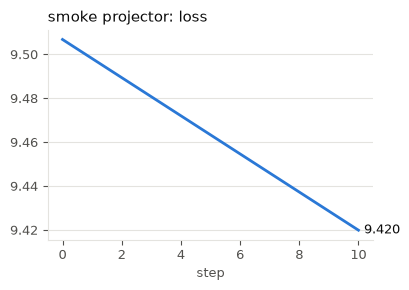

model.safetensors     random_states_1.pkl  random_states_6.pkl
optimizer.bin	      random_states_2.pkl  random_states_7.pkl
random_states_0.pkl   random_states_3.pkl  random_states_8.pkl
random_states_10.pkl  random_states_4.pkl  random_states_9.pkl
random_states_11.pkl  random_states_5.pkl  training_state.json


In [32]:
H.plot_logs({"smoke projector": SMOKE_LOG}); plt.show()
!ls {SMOKE_DIR}/checkpoints/step_final

## 12. Submitting all four stages with `qsub`

Each stage's output path is **decided here**, from `RUN_TAG`, so the next stage can be told where its input will be *before* it exists. PBS dependencies (`-W depend=afterok:<id>`) hold each job until the previous one succeeds.

```
projector (debug, 1h) ──afterok──► SFT (prod) ──afterok──► GRPO (prod, 1 tile) ──afterok──► eval SFT+GRPO
                                             └──afterok──► eval SFT
```

Step counts here are **demo-sized** (a few hundred steps); the YAML defaults are 5k / 10k / 1k. Set `SUBMIT = True` to actually submit. Otherwise the cell prints the `qsub` commands.

> If `qsub` isn't available on this compute node, copy the printed commands and run them from a login node, from `REPO`.

In [33]:
SUBMIT = False          # <- flip to submit for real

RUN = {s: f"{PRISM_CKPT_ROOT}/BIOREASON-{s.upper()}-KEGG/{RUN_TAG}" for s in ("projector", "sft", "grpo")}
CKPT_PROJ  = f"{RUN['projector']}/checkpoints/step_final"
CKPT_SFT   = f"{RUN['sft']}/checkpoints/step_final"
GRPO_ADPT  = f"{RUN['grpo']}/checkpoints/step_final/lora_adapter.pt"
EVAL_OUT   = {k: f"{PRISM_OUTPUT_ROOT}/BIOREASON-EVAL-KEGG/{RUN_TAG}/{k}.json" for k in ("sft", "sft+grpo")}
LOGS       = {k: f"{PRISM_OUTPUT_ROOT}/demo_logs/{RUN_TAG}/{k}.log"
              for k in ("projector", "sft", "grpo", "eval-sft", "eval-sft+grpo")}
common = {k: ENV[k] for k in ("PRISM_DATA_ROOT", "PRISM_OUTPUT_ROOT", "PRISM_CKPT_ROOT", "PRISM_VENV", "WANDB_MODE", "MAX_SEQ_LENGTH")} | {"RUN_TAG": RUN_TAG}

JOBS = {}
q = lambda *a, **k: H.qsub(*a, cwd=str(REPO), dry_run=not SUBMIT, **k)
JOBS["projector"] = q(PROJ_SH, {**common, "HYDRA_RUN_DIR": RUN["projector"], "MAX_STEPS": 100, "SAVE_EVERY": 50},
                      log=LOGS["projector"])
JOBS["sft"] = q(SFT_SH, {**common, "HYDRA_RUN_DIR": RUN["sft"], "STAGE1_CKPT": CKPT_PROJ, "MAX_STEPS": 500},
                depend=JOBS["projector"], log=LOGS["sft"], walltime="02:00:00")
JOBS["grpo"] = q(GRPO_SH, {**common, "HYDRA_RUN_DIR": RUN["grpo"], "STAGE1_CKPT": CKPT_SFT,
                           "MAX_STEPS": 100, "SAVE_EVERY": 50},
                 depend=JOBS["sft"], log=LOGS["grpo"])
JOBS["eval-sft"] = q(EVAL_SH, {**common, "CKPT": CKPT_SFT, "OUTPUT": EVAL_OUT["sft"]},
                     depend=JOBS["sft"], log=LOGS["eval-sft"])
JOBS["eval-sft+grpo"] = q(EVAL_SH, {**common, "CKPT": CKPT_SFT, "GRPO_ADAPTER": GRPO_ADPT, "OUTPUT": EVAL_OUT["sft+grpo"]},
                          depend=JOBS["grpo"], log=LOGS["eval-sft+grpo"])
JOBS

qsub -v PRISM_DATA_ROOT=/lus/flare/projects/ModCon/abalaji/cache,PRISM_OUTPUT_ROOT=/lus/flare/projects/ModCon/abalaji/output,PRISM_CKPT_ROOT=/lus/flare/projects/ModCon/abalaji/modcon/checkpoints,PRISM_VENV=/flare/ModCon/abalaji/prism-envs/bioreason-fw2026.1,WANDB_MODE=offline,MAX_SEQ_LENGTH=4096,RUN_TAG=demo-20261011-2324,HYDRA_RUN_DIR=/lus/flare/projects/ModCon/abalaji/modcon/checkpoints/BIOREASON-PROJECTOR-KEGG/demo-20261011-2324,MAX_STEPS=100,SAVE_EVERY=50 -o /lus/flare/projects/ModCon/abalaji/output/demo_logs/demo-20261011-2324/projector.log /lus/flare/projects/ModCon/abalaji/output/demo_scripts/demo-20261011-2324/projector.sh
qsub -v PRISM_DATA_ROOT=/lus/flare/projects/ModCon/abalaji/cache,PRISM_OUTPUT_ROOT=/lus/flare/projects/ModCon/abalaji/output,PRISM_CKPT_ROOT=/lus/flare/projects/ModCon/abalaji/modcon/checkpoints,PRISM_VENV=/flare/ModCon/abalaji/prism-envs/bioreason-fw2026.1,WANDB_MODE=offline,MAX_SEQ_LENGTH=4096,RUN_TAG=demo-20261011-2324,HYDRA_RUN_DIR=/lus/flare/projects/Mod

{'projector': 'DRYRUN',
 'sft': 'DRYRUN',
 'grpo': 'DRYRUN',
 'eval-sft': 'DRYRUN',
 'eval-sft+grpo': 'DRYRUN'}

## 13. Monitoring and results

Press **Refresh** at any time. It shows `qstat` for the chain (including finished jobs), the loss (and GRPO reward) curves parsed from each log, and the tail of each log. Each run gets its own panel, so there are no shared or dual axes.

In [34]:
H.monitor(list(JOBS.values()), {k: LOGS[k] for k in ("projector", "sft", "grpo")})

### Results

Once the eval jobs finish, compare SFT with SFT + GRPO on the KEGG test split (146 variants). `format_rate` is the share of completions with a well-formed `<answer>…</answer>`, which GRPO's format rewards push up.

In [35]:
import json
res = {k: json.load(open(p)) for k, p in EVAL_OUT.items() if Path(p).exists()}
if not res:
    print("no eval results yet")
else:
    display(pd.DataFrame({k: {"accuracy": r["accuracy"], "format_rate": r["format_rate"], "n": r["n"]}
                          for k, r in res.items()}).T)
    last = list(res)[-1]
    per = pd.DataFrame(res[last]["per_label"]).T.assign(acc=lambda d: d.correct / d.n).sort_values("n", ascending=False)
    display(per.head(15))

no eval results yet


### Quick in-process check

`eval_kegg_aurora.py` is importable, so you can score a checkpoint right here on one tile. It uses the same weight loading and prompt rendering as the batch eval.

In [36]:
from eval_kegg_aurora import load_eval_model, evaluate
ckpt = CKPT_SFT if Path(CKPT_SFT).exists() else (f"{SMOKE_DIR}/checkpoints/step_final" if Path(SMOKE_DIR).exists() else None)
print("checkpoint:", ckpt)
m, ecfg = load_eval_model(ckpt, overrides=[f"+model.dna_model_name={DNA_ENCODER}"], device=dev)
quick = evaluate(m, ecfg, DS["kegg (test)"], limit=5, max_new_tokens=128)
print({k: quick[k] for k in ("accuracy", "format_rate", "n")})
print(quick["records"][0]["completion"][:500])
del m; torch.xpu.empty_cache()

2026-10-11 23:28:34,630 - src.model - INFO - Initializing HF Backbone: allenai/OLMo-1B-0724-hf...


checkpoint: /lus/flare/projects/ModCon/abalaji/modcon/checkpoints/DEMO-SMOKE-PROJECTOR/demo-20261011-2324/checkpoints/step_final


Loading weights:   0%|          | 0/114 [00:00<?, ?it/s]

2026-10-11 23:28:36,130 - src.model - INFO - Freezing Backbone weights...
2026-10-11 23:28:36,131 - src.model - INFO - Backbone hidden dim detected: 2048
2026-10-11 23:28:36,187 - src.model - INFO - Projector config: norm_mode=l2_token, target_norm=0.25, embed_pos=after_norm, embed_scale=0.0055, hidden_mult=1, num_layers=2
2026-10-11 23:28:36,188 - src.encoders.dna - INFO - Loading DNA Encoder: /flare/ModCon/abalaji/cache/model_weights/hub/models--InstaDeepAI--nucleotide-transformer-2.5b-multi-species/snapshots/b746b125aacd1b0970c05a32fd71ba726754542e...


Loading weights:   0%|          | 0/524 [00:00<?, ?it/s]

...

[Resume] Loading model weights from /lus/flare/projects/ModCon/abalaji/modcon/checkpoints/DEMO-SMOKE-PROJECTOR/demo-20261011-2324/checkpoints/step_final/model.safetensors
[Resume] Loaded 646 weight tensors successfully
[Resume] Checkpoint was saved at step final


[INFO] DNA tokenizer loaded: /flare/ModCon/abalaji/cache/model_weights/hub/models--InstaDeepAI--nucleotide-transformer-2.5b-multi-species/snapshots/b746b125aacd1b0970c05a32fd71ba726754542e
[INFO] DNA tokenizer loaded: /flare/ModCon/abalaji/cache/model_weights/hub/models--InstaDeepAI--nucleotide-transformer-2.5b-multi-species/snapshots/b746b125aacd1b0970c05a32fd71ba726754542e
2026-10-11 23:28:53,483 - src.data.multimodal - INFO - DNA tokenizer loaded: /flare/ModCon/abalaji/cache/model_weights/hub/models--InstaDeepAI--nucleotide-transformer-2.5b-multi-species/snapshots/b746b125aacd1b0970c05a32fd71ba726754542e
[INFO] dataset_overrides applied: dna_bioreason <- {'skip': False, 'preferred_source': 'local'}
[INFO] dataset_overrides applied: dna_bioreason <- {'skip': False, 'preferred_source': 'local'}
2026-10-11 23:28:53,485 - src.data.multimodal - INFO - dataset_overrides applied: dna_bioreason <- {'skip': False, 'preferred_source': 'local'}
[INFO] dataset_overrides applied: dna_bioreason_v

DEBUG: Loading 1 Arrow files directly...


[WARNING] Skipping Variant Effect (Coding) (Configured skip)
[WARNING] Skipping Variant Effect (Coding) (Configured skip)
2026-10-11 23:28:53,808 - src.data.multimodal - WARNING - Skipping Variant Effect (Coding) (Configured skip)
[WARNING] Skipping Variant Effect (Non-SNV) (Configured skip)
[WARNING] Skipping Variant Effect (Non-SNV) (Configured skip)
2026-10-11 23:28:53,808 - src.data.multimodal - WARNING - Skipping Variant Effect (Non-SNV) (Configured skip)
[INFO] [Init] Pre-Calculated Active Modalities: [<Modality.DNA: 'dna'>]
[INFO] [Init] Pre-Calculated Active Modalities: [<Modality.DNA: 'dna'>]
2026-10-11 23:28:53,809 - src.data.multimodal - INFO - [Init] Pre-Calculated Active Modalities: [<Modality.DNA: 'dna'>]


[eval] stop token: '<|endoftext|>' (id 50279), pad id 1, max_new_tokens=128
[eval] 1/5 acc=0.000 (4s) gt='amyotrophic lateral sclerosis' pred='techtechtechtechtechtechtechtechtechtechtechtechtechtechtech'
[eval] 2/5 acc=0.000 (7s) gt='clear cell renal cell carcinoma' pred='ttttttttttttttttttttttttttttttt'
[eval] 3/5 acc=0.000 (9s) gt='melanoma' pred='ttttttttttttttttttttttttttttttt'
[eval] 4/5 acc=0.000 (11s) gt='alzheimers disease' pred='ttttttttttttttttttttttttttttttt'
[eval] 5/5 acc=0.000 (14s) gt='spinocerebellar ataxia' pred=''
{'accuracy': 0.0, 'format_rate': 0.0, 'n': 5}
TTTTTTt
Tt
Tt-Tttttt
Tttech
Tttechttechttechttechttechttechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtechtech

## 14. Troubleshooting

| Symptom | Cause / fix |
|---|---|
| `SafetensorError … Disk quota exceeded` at the first save | Checkpoints went to `outputs/` under the home checkout. Pass `hydra.run.dir=` on `/flare` (all submit scripts now do, via `HYDRA_RUN_DIR`). |
| `cannot import name 'find_pruneable_heads_and_indices'` or `EsmConfig has no attribute is_decoder` | An NT-**v2** checkpoint under transformers 5. Use an NT v1 checkpoint (e.g. 2.5B multi-species) on `frameworks/2026.1.0`. |
| DNA `input_ids` clamped / out-of-range warnings | DNA tokenizer and encoder came from different NT releases. The tokenizer now follows `model.dna_model_name`, so keep them the same. |
| `torch_geometric` / IPEX import errors in the kernel | Venv activated before `module load frameworks`. Use the `prism-bioreason` kernel (its wrapper loads them in order). |
| `IndexError` in DDP side streams / "device index out of range" | Each rank must see one tile as `xpu:0`: `ZE_AFFINITY_MASK=$LOCAL_RANK` and `LOCAL_RANK=0` (the scripts' `mpiexec` block). |
| Training hangs at the first batch on compute nodes | Hub access attempted offline. Check `HF_HUB_OFFLINE=1` and that section 3 populated `$HF_HOME/hub` and `$PRISM_DATA_ROOT/dna_local_shards`. |
| GRPO job uses one tile only | By design: `ZoneDTrainer` is single-process (no DDP/vLLM yet). |
| `Merged sequence length 2798 … exceeds max_merged_seq_length=2048` | Set `MAX_SEQ_LENGTH=4096` (section 1; the GRPO/eval scripts default to it). Or lower `training.max_dna_length`. |
| Model echoes `Reference sequence: 5029250293`, or the DNA projector gets no gradient | Tag ids were rendered as text, so DNA was never spliced. Fixed in `_render_dna_prompt_text`. The section 10 assertion guards against it. |
| `ImportError: eval_kegg` during SFT | `training.eval_enabled=true` calls the not-yet-merged `eval_kegg.py`. Keep it `false` and use `eval_kegg_aurora.py`. |